In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="target")

print("Shape of X:", X.shape)
print("Target classes:", data.target_names)

X.head()

Shape of X: (569, 30)
Target classes: ['malignant' 'benign']


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", round(accuracy, 4))
print(classification_report(y_test, y_pred, target_names=data.target_names))

Accuracy: 0.9561
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [5]:
sample_index = 0

sample = X_test.iloc[[sample_index]]
true_label = y_test.iloc[sample_index]
predicted_label = model.predict(sample)[0]
predicted_proba = model.predict_proba(sample)[0]

print("True label:", data.target_names[true_label])
print("Predicted label:", data.target_names[predicted_label])

print("\nPrediction probabilities:")
for class_name, probability in zip(data.target_names, predicted_proba):
    print(f"{class_name}: {probability:.4f}")

True label: malignant
Predicted label: malignant

Prediction probabilities:
malignant: 1.0000
benign: 0.0000


In [6]:
# Find a less extreme prediction to make the explanation more interesting

probas = model.predict_proba(X_test)

# For each prediction, take the probability of the predicted class
max_probas = probas.max(axis=1)

# Sort by uncertainty: lower max probability means the model was less certain
uncertain_indices = np.argsort(max_probas)

for idx in uncertain_indices[:10]:
    true_label = y_test.iloc[idx]
    predicted_label = model.predict(X_test.iloc[[idx]])[0]
    predicted_proba = model.predict_proba(X_test.iloc[[idx]])[0]
    
    print("Index:", idx)
    print("True label:", data.target_names[true_label])
    print("Predicted label:", data.target_names[predicted_label])
    print("Probabilities:", dict(zip(data.target_names, np.round(predicted_proba, 4))))
    print("-" * 50)

Index: 16
True label: benign
Predicted label: benign
Probabilities: {np.str_('malignant'): np.float64(0.495), np.str_('benign'): np.float64(0.505)}
--------------------------------------------------
Index: 110
True label: benign
Predicted label: benign
Probabilities: {np.str_('malignant'): np.float64(0.405), np.str_('benign'): np.float64(0.595)}
--------------------------------------------------
Index: 48
True label: benign
Predicted label: benign
Probabilities: {np.str_('malignant'): np.float64(0.37), np.str_('benign'): np.float64(0.63)}
--------------------------------------------------
Index: 53
True label: malignant
Predicted label: benign
Probabilities: {np.str_('malignant'): np.float64(0.365), np.str_('benign'): np.float64(0.635)}
--------------------------------------------------
Index: 45
True label: benign
Predicted label: benign
Probabilities: {np.str_('malignant'): np.float64(0.355), np.str_('benign'): np.float64(0.645)}
--------------------------------------------------
Ind

In [7]:
selected_index = 16

sample = X_test.iloc[[selected_index]]
sample_array = X_test.iloc[selected_index].values

true_label = y_test.iloc[selected_index]
predicted_label = model.predict(sample)[0]
predicted_proba = model.predict_proba(sample)[0]

print("Selected index:", selected_index)
print("True label:", data.target_names[true_label])
print("Predicted label:", data.target_names[predicted_label])

print("\nPrediction probabilities:")
for class_name, probability in zip(data.target_names, predicted_proba):
    print(f"{class_name}: {probability:.4f}")

Selected index: 16
True label: benign
Predicted label: benign

Prediction probabilities:
malignant: 0.4950
benign: 0.5050


In [8]:
from lime.lime_tabular import LimeTabularExplainer
from pathlib import Path

In [12]:


lime_explainer = LimeTabularExplainer(
    training_data=X_train.values,
    feature_names=X_train.columns.tolist(),
    class_names=data.target_names.tolist(),
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

def predict_proba_for_lime(x):
    x_df = pd.DataFrame(x, columns=X_train.columns)
    return model.predict_proba(x_df)

lime_exp = lime_explainer.explain_instance(
    data_row=sample_array,
    predict_fn=predict_proba_for_lime,
    num_features=10,
    top_labels=2
)

In [13]:
lime_results = pd.DataFrame(
    lime_exp.as_list(label=predicted_label),
    columns=["Feature condition", "LIME contribution"]
)

lime_results

,Feature condition,LIME contribution
0,worst concavity > 0.39,-0.043266
1,worst texture > 29.37,-0.040260
2,mean texture > 21.71,-0.027548
3,97.59 < worst perimeter <= 124.95,-0.023581
4,683.40 < worst area <= 1033.50,-0.019785
5,541.80 < mean area <= 770.05,0.014358
6,0.13 < worst smoothness <= 0.15,-0.013622
7,worst fractal dimension > 0.09,-0.012233
8,17.73 < area error <= 24.25,0.011661
9,fractal dimension error > 0.00,0.011216


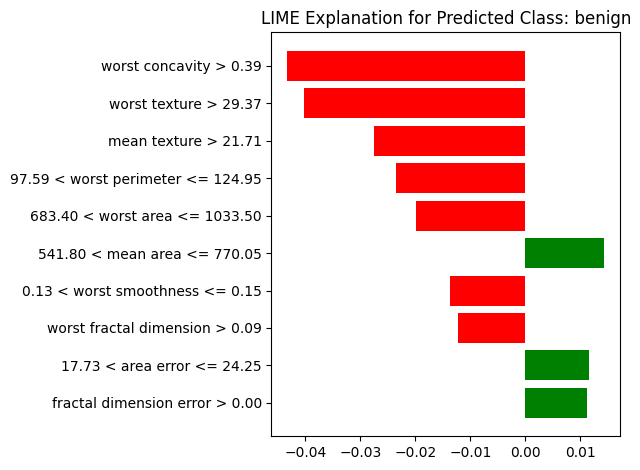

In [14]:
fig = lime_exp.as_pyplot_figure(label=predicted_label)

plt.title(f"LIME Explanation for Predicted Class: {data.target_names[predicted_label]}")
plt.tight_layout()

figures_dir = Path("../figures")
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(figures_dir / "lime_explanation.png", dpi=300, bbox_inches="tight")
plt.show()

In [16]:
import shap

shap_explainer = shap.TreeExplainer(model)

shap_values_raw = shap_explainer.shap_values(sample)
expected_value_raw = shap_explainer.expected_value

In [17]:
# Get SHAP values for the predicted class safely
# predicted_label = 0 means malignant
# predicted_label = 1 means benign

if isinstance(shap_values_raw, list):
    shap_values_for_class = shap_values_raw[predicted_label][0]
    expected_value_for_class = expected_value_raw[predicted_label]
else:
    shap_values_for_class = shap_values_raw[0, :, predicted_label]
    expected_value_for_class = expected_value_raw[predicted_label]

shap_explanation = shap.Explanation(
    values=shap_values_for_class,
    base_values=expected_value_for_class,
    data=sample.iloc[0].values,
    feature_names=X.columns
)

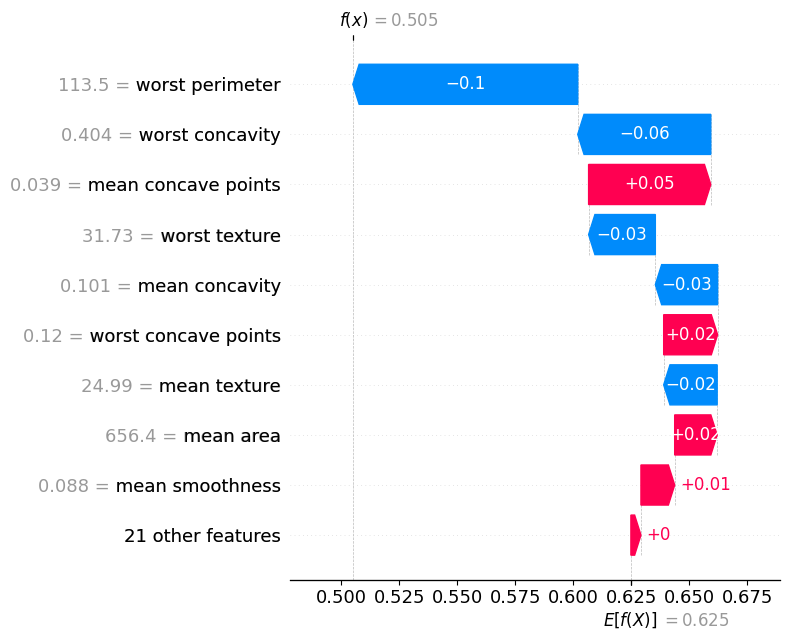

In [18]:
plt.figure()

shap.plots.waterfall(
    shap_explanation,
    max_display=10,
    show=False
)

plt.tight_layout()
plt.savefig(figures_dir / "shap_waterfall.png", dpi=300, bbox_inches="tight")
plt.show()

In [19]:
shap_results = pd.DataFrame({
    "Feature": X.columns,
    "Feature value": sample.iloc[0].values,
    "SHAP contribution": shap_values_for_class
})

shap_results["Absolute contribution"] = shap_results["SHAP contribution"].abs()

shap_results = shap_results.sort_values(
    by="Absolute contribution",
    ascending=False
)

shap_results.head(10)

,Feature,Feature value,SHAP contribution,Absolute contribution
22,worst perimeter,113.50000,-0.096960,0.096960
26,worst concavity,0.40400,-0.057350,0.057350
7,mean concave points,0.03890,0.052666,0.052666
21,worst texture,31.73000,-0.028774,0.028774
6,mean concavity,0.10090,-0.026850,0.026850
27,worst concave points,0.12050,0.023258,0.023258
1,mean texture,24.99000,-0.023059,0.023059
3,mean area,656.40000,0.018313,0.018313
4,mean smoothness,0.08837,0.014547,0.014547
25,worst compactness,0.42020,-0.014358,0.014358


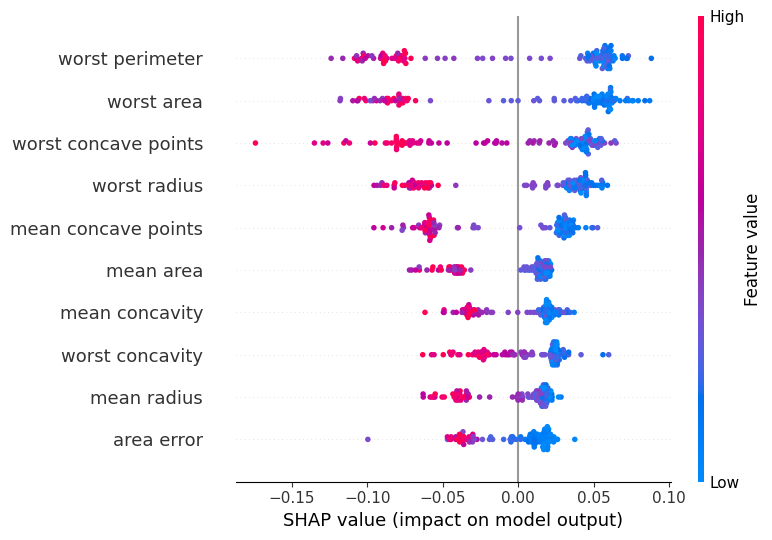

In [20]:
shap_values_test_raw = shap_explainer.shap_values(X_test)

if isinstance(shap_values_test_raw, list):
    shap_values_test_for_class = shap_values_test_raw[predicted_label]
else:
    shap_values_test_for_class = shap_values_test_raw[:, :, predicted_label]

shap.summary_plot(
    shap_values_test_for_class,
    X_test,
    max_display=10,
    show=False
)

plt.tight_layout()
plt.savefig(figures_dir / "shap_summary.png", dpi=300, bbox_inches="tight")
plt.show()

In [21]:
lime_results_sorted = lime_results.copy()
lime_results_sorted["Absolute contribution"] = lime_results_sorted["LIME contribution"].abs()
lime_results_sorted = lime_results_sorted.sort_values(
    by="Absolute contribution",
    ascending=False
).reset_index(drop=True)

lime_results_sorted.head(10)

,Feature condition,LIME contribution,Absolute contribution
0,worst concavity > 0.39,-0.043266,0.043266
1,worst texture > 29.37,-0.040260,0.040260
2,mean texture > 21.71,-0.027548,0.027548
3,97.59 < worst perimeter <= 124.95,-0.023581,0.023581
4,683.40 < worst area <= 1033.50,-0.019785,0.019785
5,541.80 < mean area <= 770.05,0.014358,0.014358
6,0.13 < worst smoothness <= 0.15,-0.013622,0.013622
7,worst fractal dimension > 0.09,-0.012233,0.012233
8,17.73 < area error <= 24.25,0.011661,0.011661
9,fractal dimension error > 0.00,0.011216,0.011216


In [22]:
comparison_df = pd.DataFrame({
    "LIME top features": lime_results_sorted["Feature condition"].head(6),
    "LIME contribution": lime_results_sorted["LIME contribution"].head(6).round(4),
    "SHAP top features": shap_results["Feature"].head(6).values,
    "SHAP contribution": shap_results["SHAP contribution"].head(6).round(4).values
})

comparison_df

,LIME top features,LIME contribution,SHAP top features,SHAP contribution
0,worst concavity > 0.39,-0.0433,worst perimeter,-0.0970
1,worst texture > 29.37,-0.0403,worst concavity,-0.0574
2,mean texture > 21.71,-0.0275,mean concave points,0.0527
3,97.59 < worst perimeter <= 124.95,-0.0236,worst texture,-0.0288
4,683.40 < worst area <= 1033.50,-0.0198,mean concavity,-0.0269
5,541.80 < mean area <= 770.05,0.0144,worst concave points,0.0233


In [23]:
comparison_df.to_csv("../reports/lime_shap_comparison.csv", index=False)